In [ ]:
import numpy as np

# Hitung jarak antar kota dengan rumus euclidian distance
path_distance = lambda r,c: np.sum([np.linalg.norm(c[r[p]]-c[r[p-1]]) for p in range(len(r))])


# Membalikkan urutan (reverse) semua elemen dari elemen i hingga elemen k dalam array r.
two_opt_swap = lambda r,i,k: np.concatenate((r[0:i],r[k:-len(r)+i-1:-1],r[k+1:len(r)]))

def two_opt(cities,improvement_threshold): # 2-opt Algorithm baca lebih lengkap di https://en.wikipedia.org/wiki/2-opt
    route = np.arange(cities.shape[0]) # Buat array baris yang sesuai dengan kota.
    improvement_factor = 1 # Initialize untuk perbaikan.
    best_distance = path_distance(route,cities) # Hitung jarak dari jalur awal.

    while improvement_factor > improvement_threshold: # Kalau rute masih bisa lebih baik, keep going!
        distance_to_beat = best_distance # Simpan jarak terbaik ya.

        for swap_first in range(1,len(route)-2): # Selalu cari kota awal dan kota terakhir, nanti di swap.
            for swap_last in range(swap_first+1,len(route)):
                new_route = two_opt_swap(route,swap_first,swap_last) # Kalau ada rute terbaik simpan.
                new_distance = path_distance(new_route,cities) # selalu cek jarak setiap kali ada rute terbaik.

                if new_distance < best_distance: # Kalau ada rute terbaik simpan.
                    route = new_route # catat sebagai best route.
                    best_distance = new_distance # update jangan lupa.
        improvement_factor = 1 - best_distance/distance_to_beat # Hitung rute terbaik.
    return route # Kalau rute sudah gak improving lagi ya berhenti pencariannya dan kembalikan rute-nya.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cities50 (1).csv to cities50 (1).csv


In [ ]:
import pandas as pd
cities2= pd.read_csv("cities50.csv")
cities2.head()

FileNotFoundError: [Errno 2] No such file or directory: 'cities50.csv'

In [ ]:
from math import radians,cos,sin

lat =cities2["latitude"].map(radians)
lon = cities2["longitude"].map(radians)
x = lon.map(cos)*lat.map(cos)*6371
y= lon.map(cos)*lat.map(sin)*6371

cities2["lat_radians"] = lat
cities2["lon_radians"] = lon
cities2["x"] = x
cities2["y"] = y
cities2.head()

,name,description,latitude,longitude,lat_radians,lon_radians,x,y
0,Alabama,Montgomery,32.377716,-86.300568,0.565098,-1.506229,347.165470,220.128552
1,Alaska,Juneau,58.301598,-134.420212,1.017555,-2.346075,-2343.056680,-3793.968746
2,Arizona,Phoenix,33.448143,-112.096962,0.583780,-1.956461,-1999.696985,-1320.969349
3,Arkansas,Little Rock,34.746613,-92.288986,0.606443,-1.610747,-209.081510,-145.026698
4,California,Sacramento,38.576668,-121.493629,0.673290,-2.120464,-2601.928590,-2075.358090


In [ ]:
# Hapus kolom-kolom dan tinggalkan kolom x dan y saja
cities = cities2.drop(columns=["name", "description", "latitude", "longitude", "lat_radians", "lon_radians"])
cities.head()
# cities2.head

,x,y
0,347.165470,220.128552
1,-2343.056680,-3793.968746
2,-1999.696985,-1320.969349
3,-209.081510,-145.026698
4,-2601.928590,-2075.358090


In [ ]:
df = cities.copy()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 100), copy=True)
scaled_df = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled_df, columns=['x1', 'x2'])

In [ ]:
cities = np.asarray(cities)

In [ ]:
scaled = np.asarray(scaled_df)

In [ ]:
route = two_opt(scaled,0.001) # Jalankan algoritma 2-opt, improvement_threshold 0.001

# print jarak terpendek
print(path_distance(route,scaled))

# simpan hasil route kedalam dataframe
df_route = pd.DataFrame(route, columns=['route'])
df_route.head()

# gabungkan city dan route kedalam satu dataframe
result = pd.concat([cities2, df_route], axis=1)

# tampilkan hasil dataframe
result.head()

315.8765978025802


,name,description,latitude,longitude,lat_radians,lon_radians,x,y,route
0,Alabama,Montgomery,32.377716,-86.300568,0.565098,-1.506229,347.165470,220.128552,0
1,Alaska,Juneau,58.301598,-134.420212,1.017555,-2.346075,-2343.056680,-3793.968746,9
2,Arizona,Phoenix,33.448143,-112.096962,0.583780,-1.956461,-1999.696985,-1320.969349,10
3,Arkansas,Little Rock,34.746613,-92.288986,0.606443,-1.610747,-209.081510,-145.026698,39
4,California,Sacramento,38.576668,-121.493629,0.673290,-2.120464,-2601.928590,-2075.358090,31


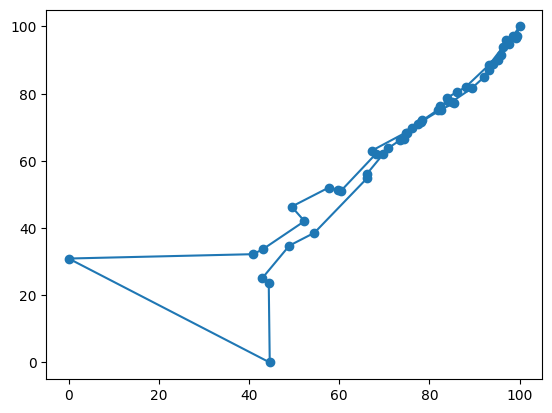

Route: [ 0  9 10 39 31 45 19  7 29  6 38 20 18 28 44 33 37 47 34 21 16 13 41 48
 17  3 42 35 49  5 30  2 43 27  4  8  1 46 36 11 25 32 40 26 15 14 22 24
 23 12]

Distance_scaled: 315.8765978025802


In [ ]:
#Tampilkan dalam bentuk Diagram CARTESIAN

import matplotlib.pyplot as plt
# Susun ulang kota (re-order).
new_cities_order = np.concatenate((np.array([scaled[route[i]] for i in range(len(route))]),np.array([scaled[0]])))
# Plotting kota-kota.
plt.scatter(scaled[:,0],scaled[:,1])
# Plotting jalur.
plt.plot(new_cities_order[:,0],new_cities_order[:,1])
plt.show()
# Tampilkan rute sebagai nomor baris dan total jarak berdasarkan path/jalur.
print("Route: " + str(route) + "\n\nDistance_scaled: " + str(path_distance(route,scaled)))

In [ ]:
Distance_km = path_distance(route, scaled) * 53.31
Distance_km

16839.38142885555

In [ ]:
order = pd.DataFrame(route, columns=["index"])
cities2["index"] = cities2.index
cities2
travel=order.merge(cities2, on ="index")

In [ ]:
start= travel [0:1]
loop = travel._append(start)
loop

,index,name,description,latitude,longitude,lat_radians,lon_radians,x,y
0,0,Alabama,Montgomery,32.377716,-86.300568,0.565098,-1.506229,347.165470,220.128552
1,9,Florida,Tallahassee,30.438118,-84.281296,0.531245,-1.470986,547.340539,321.612456
2,10,Georgia,Atlanta<br>,33.749027,-84.388229,0.589032,-1.472852,518.014165,346.113275
3,39,South Carolina,Columbia,34.000343,-81.033211,0.593418,-1.414296,823.227985,555.281457
4,31,North Carolina,Raleigh,35.780430,-78.639099,0.624486,-1.372511,1018.146153,733.781645
5,45,Virginia,Richmond,37.538857,-77.433640,0.655177,-1.351472,1099.126150,844.574072
6,19,Maryland,Annapolis,38.978764,-76.490936,0.680308,-1.335019,1156.942631,936.163885
7,7,Delaware,Dover,39.157307,-75.519722,0.683424,-1.318068,1235.273492,1005.932711
8,29,New Jersey,Trenton,40.220596,-74.769913,0.701982,-1.304981,1277.927754,1080.720351
9,6,Connecticut,Hartford<br>,41.764046,-72.682198,0.728920,-1.268544,1414.562207,1263.168205


In [ ]:
#SIMPAN RUTE DALAM BENTUK CSV

tsp = loop[["latitude", "longitude"]]
tsp.to_csv('tsp.csv', index=False)
from google.colab import files
files.download("tsp.csv")